In [27]:
import re

pattern = re.compile(r".*\t([\d\w]+)")


def parse_log(log: str) -> tuple[list[int], list[int]]:
    X: list[int] = []
    Y: list[int] = []
    current = X
    for l in log.strip().split("\n"):
        v = re.match(pattern, l).groups()[0]
        if v.isdigit():
            current.append(int(v))
        elif v == "Y":
            current = Y

    return X, Y

In [28]:
res = """\
[WARN] GBA Debug:	X
[WARN] GBA Debug:	0
[WARN] GBA Debug:	74
[WARN] GBA Debug:	96
[WARN] GBA Debug:	111
[WARN] GBA Debug:	136
[WARN] GBA Debug:	257
[WARN] GBA Debug:	260
[WARN] GBA Debug:	300
[WARN] GBA Debug:	Y
[WARN] GBA Debug:	0
[WARN] GBA Debug:	6
[WARN] GBA Debug:	49
[WARN] GBA Debug:	74
[WARN] GBA Debug:	100
"""
# res = """\
# [WARN] GBA Debug:	X
# [WARN] GBA Debug:	0
# [WARN] GBA Debug:	15
# [WARN] GBA Debug:	21
# [WARN] GBA Debug:	197
# [WARN] GBA Debug:	214
# [WARN] GBA Debug:	218
# [WARN] GBA Debug:	246
# [WARN] GBA Debug:	300
# [WARN] GBA Debug:	Y
# [WARN] GBA Debug:	0
# [WARN] GBA Debug:	3
# [WARN] GBA Debug:	31
# [WARN] GBA Debug:	39
# [WARN] GBA Debug:	100
# """

Xs, Ys = parse_log(res)
print(Xs, Ys)

[0, 74, 96, 111, 136, 257, 260, 300] [0, 6, 49, 74, 100]


In [29]:
# steps = 1

# Xs = [0, 1, 18, 113, 147, 222, 259, 300]
# Ys = [0, 60, 87, 94, 100]

# Xs = [0, 33, 66, 99]
# Ys = [0, 25, 40]

last_kf = 0


def map_(t: int, x1: int, x2: int, y1: int, y2: int) -> int:
    x_ = x2 - x1
    t_ = t - x1
    y_ = y2 - y1
    return y1 + (t_ * y_) / x_


def step_inter(x: int) -> int:
    global last_kf
    if Xs[last_kf] <= x < Xs[last_kf + 1]:
        pass
    else:
        for i in range(len(Xs) - 1):
            if Xs[i] <= x < Xs[i + 1]:
                last_kf = i
                break
    if last_kf % 2 == 1:
        return Ys[(last_kf + 1) // 2]

    y_ind = last_kf // 2
    return map_(x, Xs[last_kf], Xs[last_kf + 1], Ys[y_ind], Ys[y_ind + 1])


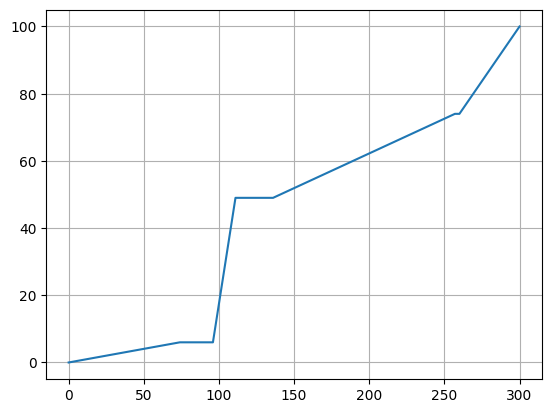

In [30]:
import matplotlib.pyplot as plt
import numpy as np

a = step_inter(0)


# Data for plotting
X = list(range(Xs[0], Xs[-1] + 1))
Y = [step_inter(x) for x in X]

fig, ax = plt.subplots()
ax.plot(X, Y)

ax.grid()

# fig.savefig("test.png")
plt.show()